In [1]:
from astroquery.ipac.irsa import Irsa
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
import os
import sys
sys.path.append('../')
from src import *
import astropy
from astropy.coordinates import SkyCoord
from astropy import units as u
import warnings
from astropy.wcs import WCS, FITSFixedWarning
import logging
logging.getLogger('astropy.wcs').setLevel(logging.ERROR)
from erfa import ErfaWarning
warnings.filterwarnings(
    "ignore",
    category=ErfaWarning,
    message='.*pmsafe.*distance overridden.*'
)


In [2]:
# Ignore FITSFixedWarning specifically
warnings.filterwarnings('ignore', category=FITSFixedWarning)

In [3]:
### Starndards L/T dwarfs
#known_data = Table.read('../Data/standards/standards.csv')
#path_figures = '../Figures/standards/'
#path_data = '../Data/standards/'

### Standards young L/T dwarfs
known_data = Table.read('../Data/tables/youngstandards.csv')
path_figures = '../Figures/'
path_data = '../Data/spectra/'

### Disk Claire
#known_data = Table.read('../Data/disk_claire/disk_claire.csv')
#mask = np.array([str(x)!='-' and str(x)!='--' for x in known_data['pmra']])
#known_data = known_data[mask]
#ra,dec = [],[]
#for ra_i,dec_i in zip(known_data['ra'],known_data['dec']):
#    c = SkyCoord(ra_i+' '+dec_i, unit=(u.hourangle, u.deg))
#    ra.append(c.ra.deg)
#    dec.append(c.dec.deg)
#known_data['ra'] = ra
#known_data['dec'] = dec
#for column in ['pmra','pmdec','epoch']:
#    known_data[column] = np.array([float(x) for x in known_data[column]])

### Young LT dwarfs
#youngLTdwarfs = Table.read('../Data/youngLTdwarfs/youngLTdwarfs.csv')
#youngLTdwarfs = youngLTdwarfs[np.array(youngLTdwarfs['sptnum_ir_formula']) >= 10]
#known_data = Table()
#known_data['Name'] = youngLTdwarfs['name']
#known_data['ra'] = youngLTdwarfs['ra_j2000_P1']
#known_data['dec'] = youngLTdwarfs['dec_j2000_P1']
#known_data['pmra'] = youngLTdwarfs['pmra_formula']
#known_data['pmdec'] = youngLTdwarfs['pmdec_formula']
#known_data['epoch'] = np.ones(len(youngLTdwarfs))*2000
#path_figures = '../Figures/youngLTdwarfs/'
#path_data = '../Data/youngLTdwarfs/'

###subdwarfs
#subdwarfs = Table.read('../Data/subdwarfs/subdwarfs.csv')
#subdwarfs = subdwarfs[np.array(subdwarfs['sptnum_ir_formula']) < -10]
#known_data = Table()
#known_data['Name'] = subdwarfs['name']
#known_data['ra'] = subdwarfs['ra_j2000_WISE']
#known_data['dec'] = subdwarfs['dec_j2000_WISE']
#known_data['pmra'] = subdwarfs['pmra_formula']
#known_data['pmdec'] = subdwarfs['pmdec_formula']
#known_data['epoch'] = np.ones(len(subdwarfs))*2000
#path_figures = '../Figures/subdwarfs/'
#path_data = '../Data/subdwarfs/'
    

In [4]:
print(len(known_data))

154


In [5]:
known_data

Name,SpT,SpT_ir,literature_flag,youth_evidence,age_category,age_category_justification,ra,dec,pmra,pmdec,epoch,J,J_err,H,H_err,K,K_err
str31,float64,float64,str22,str12,str25,str22,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2MASS J00011217+1535355,13.7,13.7,lowg,YMG;lowg,ABDMG,UCS+BANYAN,0.3006871,15.5932068,143.485,-174.725,2000.0,15.522,0.062,14.505,0.044,13.71,0.044
2MASS J00133470+1109403,11.0,11.0,lowg,lowg,INT-G,Kell17,3.394595,11.161202,66.0,-45.0,2000.0,15.721,0.075,14.707,0.062,14.225,0.067
2MASS J00182834-6703130,10.4,10.4,lowg,YMG;lowg,THA,UCS+BANYAN,4.6180279,-67.0536165,86.217,-55.157,2000.0,15.457,0.059,14.48,0.04,13.711,0.04
2MASS J00191296-6226005,11.0,11.0,lowg,YMG;lowg,THA,UCS+BANYAN,4.8038411,-62.4334485,88.1,-54.504,2000.0,15.64,0.061,14.618,0.052,13.957,0.052
2MASS J00193927-3724392,13.0,12.2,lowg,lowg,INT-G,Gagn15c,4.9137289,-37.4109014,165.466,17.308,2000.0,15.519,0.06,14.47,0.058,13.689,0.058
PC 0025+0447,9.5,10.0,lowg,lowg,beta,Fahe16;Alle13a,6.9249239,5.061581,16.1,-3.3,2000.0,16.189,0.093,15.288,0.116,14.964,0.116
EROS-MP J0032-4405,10.0,10.0,plx-discrep;lowg,YMG;lowg,ABDMG!,UCS+BANYAN,8.2326981,-44.0849345,127.841,-96.832,2000.0,14.776,0.035,13.857,0.037,13.269,0.037
2MASS J00332386-1521309,14.0,11.0,lowg;young,lowg,beta+FLD-G,Cruz09;Alle13a,8.349467,-15.358583,302.129,25.154,2000.0,15.286,0.056,14.208,0.039,13.41,0.039
2MASS J00344300-4102266,11.5,11.5,lowg,lowg,VL-G,Gagn15c,8.6791596,-41.0407223,107.909,-59.276,2000.0,15.707,0.067,14.807,0.056,14.084,0.056


In [6]:
known_data[36]

Name,SpT,SpT_ir,literature_flag,youth_evidence,age_category,age_category_justification,ra,dec,pmra,pmdec,epoch,J,J_err,H,H_err,K,K_err
str31,float64,float64,str22,str12,str25,str22,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2MASS J03231002-4631237,10.0,9.4,lowg,YMG;lowg,THA!,UCS+BANYAN,50.7917104,-46.5232175,85.546,-7.323,2000.0,15.389,0.07,14.321,0.05,13.702,0.05


147 out of 154
2MASS J23153135+0617146
0 out of 193:https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W25_1B/l2b-v20-2025-253/3/level2_2025W25_1B_0134_1D3_spx_l2b-v20-2025-253.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here

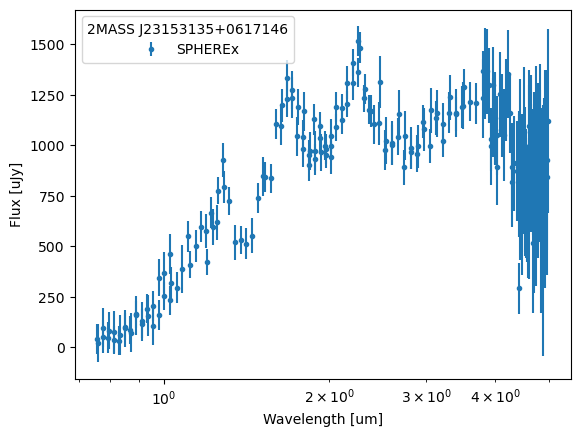

148 out of 154
2MASS J23174712-4838501
0 out of 225:https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W20_1C/l2b-v20-2025-247/2/level2_2025W20_1C_0195_1D2_spx_l2b-v20-2025-247.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here

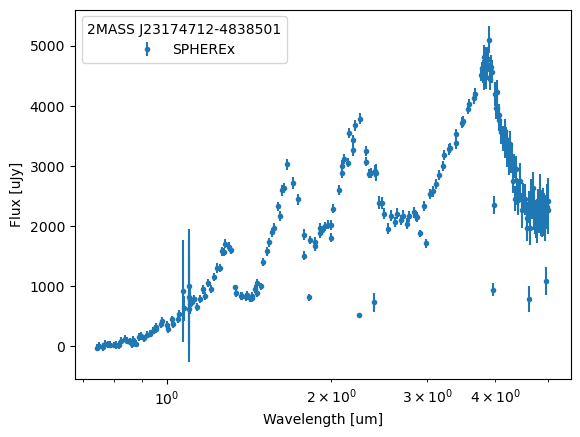

149 out of 154
2MASS J23224684-3133231
0 out of 221:https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W22_1B/l2b-v20-2025-250/5/level2_2025W22_1B_0043_1D5_spx_l2b-v20-2025-250.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here

In [ ]:

perc = 0.9 # Percentage of flux to choose r_aperture

for i_known_data in range(len(known_data)):
    name = known_data['Name'][i_known_data]
    ra_deg = known_data['ra'][i_known_data]
    dec_deg = known_data['dec'][i_known_data]
    pmra = known_data['pmra'][i_known_data]
    pmdec = known_data['pmdec'][i_known_data]
    epoch = known_data['epoch'][i_known_data]

    if not os.path.exists(path_data+'Spherex_spec_'+name+'.csv'):
        print(f'{i_known_data} out of {len(known_data)}')

        coord = SkyCoord(ra_deg, dec_deg, unit='deg')
        search_radius = 1 * u.arcsec
        print(name)

        results_spec = Table()

        # Following tutorial https://caltech-ipac.github.io/irsa-tutorials/spherex-intro/
        Irsa.list_collections(filter='spherex')

        results = Irsa.query_sia(pos=(coord, search_radius), collection='spherex_qr2')

        if not os.path.exists(path_figures + name+'/'):
            os.makedirs(path_figures + name+'/')

        test_external_ring = False

        results_spec = extrac_spectrum(name,results,results_spec,ra_deg,dec_deg,pmra,pmdec,epoch,perc,
                                       test_external_ring,known_data,i_known_data,path_figures,path_data)#,increase_ring=5)
        results_spec.sort('Wave [um] '+str(perc))
        results_spec.write(path_data+'Spherex_spec_'+name+'.csv',format='csv',overwrite=True)
        

17 out of 19
WISE J024124.73-365328.0
0 out of 117:https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W28_2A/l2b-v20-2025-260/6/level2_2025W28_2A_0551_2D6_spx_l2b-v20-2025-260.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here,

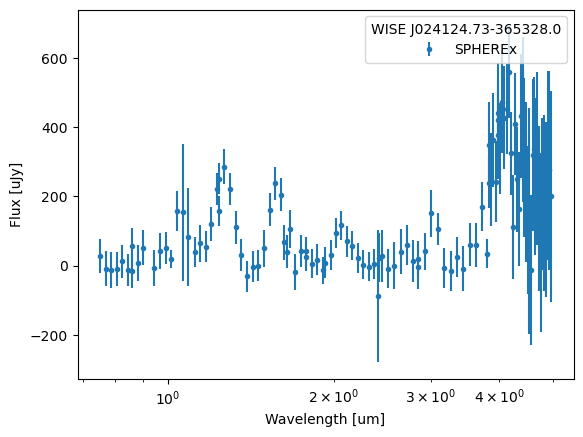

6 out of 19
2MASS J22273685-1854531
0 out of 283:https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W45_1A/l2b-v20-2025-311/3/level2_2025W45_1A_0324_3D3_spx_l2b-v20-2025-311.fits
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, i

KeyboardInterrupt: 

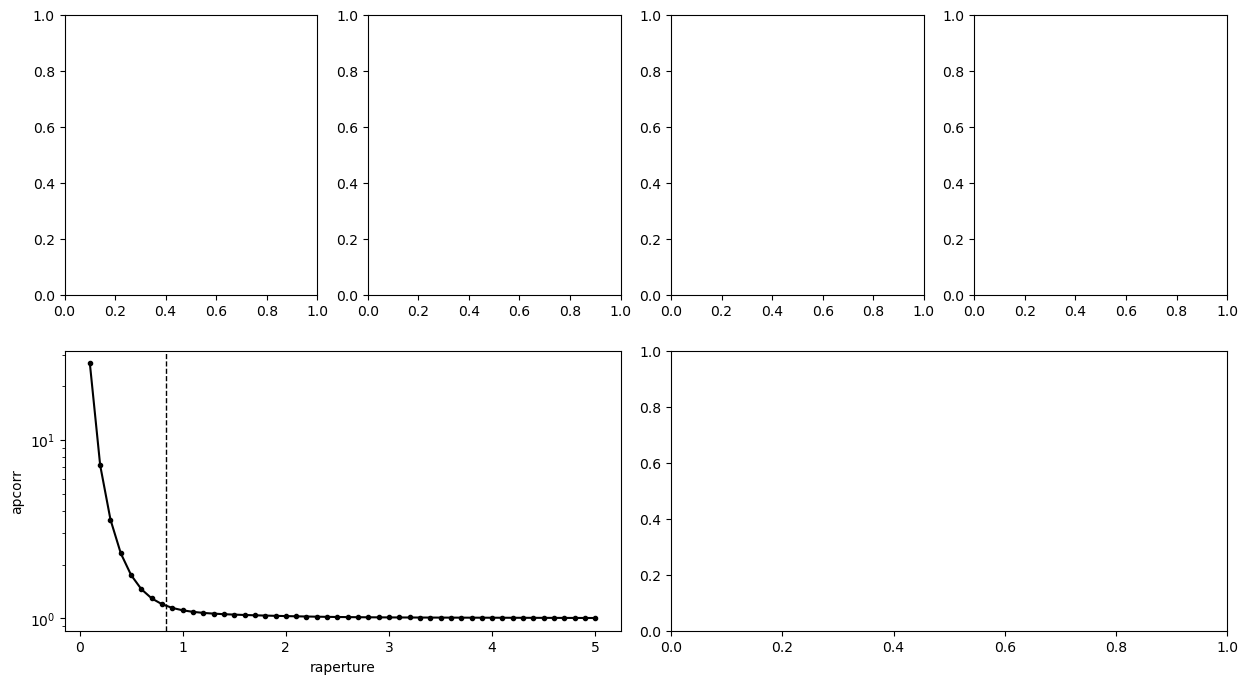

In [5]:

perc = 0.85 # Percentage of flux to choose r_aperture

for i_known_data in [13, 16, 17, 6]:

    name = known_data['Name'][i_known_data]
    ra_deg = known_data['ra'][i_known_data]
    dec_deg = known_data['dec'][i_known_data]
    pmra = known_data['pmra'][i_known_data]
    pmdec = known_data['pmdec'][i_known_data]
    epoch = known_data['epoch'][i_known_data]

    if not os.path.exists(path_data+'Spherex_spec_'+name+'.csv'):
        print(f'{i_known_data} out of {len(known_data)}')

        coord = SkyCoord(ra_deg, dec_deg, unit='deg')
        search_radius = 1 * u.arcsec
        print(name)

        results_spec = Table()

        # Following tutorial https://caltech-ipac.github.io/irsa-tutorials/spherex-intro/
        Irsa.list_collections(filter='spherex')

        results = Irsa.query_sia(pos=(coord, search_radius), collection='spherex_qr2')

        if not os.path.exists(path_figures + name+'/'):
            os.makedirs(path_figures + name+'/')

        test_external_ring = False

        results_spec = extrac_spectrum(name,results,results_spec,ra_deg,dec_deg,pmra,pmdec,epoch,perc,
                                        test_external_ring,known_data,i_known_data,path_figures,path_data)#,increase_ring=5)
        results_spec.sort('Wave [um] '+str(perc))
        results_spec.write(path_data+'Spherex_spec_'+name+'.csv',format='csv',overwrite=True)
            

In [17]:
spectral_image_header = hdulist[1].header
psf_header = hdulist[5].header
psfcube = hdulist[5].data
flags_header = hdulist[2].header
flags_data = hdulist[2].data
image_data = hdulist[1].data
image_data_err = np.sqrt(hdulist[3].data)

In [18]:
# Get coordinates in real world transformation
new_ra, new_dec = move_forward_position(ra_deg,dec_deg,pmra,pmdec,epoch,results['t_min'][i])
wcs = WCS(spectral_image_header)
# Get pixel position for relevant coord
x_rel, y_rel = wcs.world_to_pixel(SkyCoord(ra=new_ra, dec=new_dec, unit="deg"))

In [22]:
positions = [(x_rel, y_rel)]
make_big = 100
r_in, r_out = make_big*8,make_big*10
#flags for photometry background
flags = ['OVERFLOW', 'SUR_ERROR', 'NONFUNC', 'MISSING_DATA', 'HOT', 'COLD', 'NONLINEAR',
        'PERSIST', 'OUTLIER', 'TRANSIENT']
mask_bkg = define_mask(flags, flags_header, flags_data)
data_bkg_clean = np.where(mask_bkg, image_data, np.nan)
data_bkg_err_clean = np.where(mask_bkg, image_data_err, np.nan)

# Calculate background flux
annulus_aperture, bkg_stats = background_aperture(data_bkg_clean, positions, r_in, r_out, data_bkg_err_clean)
bkg_stats.median


array([0.17837694])

(array([  422.,   760.,  1176.,  1830.,  2954.,  4365.,  6486.,  8935.,
        11966., 15526., 19819., 24802., 29904., 35060., 40151., 44724.,
        49041., 52303., 54110., 55107., 54233., 52489., 49917., 46423.,
        42318., 38079., 33411., 28951., 24320., 20058., 16085., 12870.,
         9852.,  7742.,  6006.,  4762.,  3724.,  3173.,  2623.,  2322.]),
 array([0.1255188, 0.1281618, 0.1308048, 0.1334478, 0.1360908, 0.1387338,
        0.1413768, 0.1440198, 0.1466628, 0.1493058, 0.1519488, 0.1545918,
        0.1572348, 0.1598778, 0.1625208, 0.1651638, 0.1678068, 0.1704498,
        0.1730928, 0.1757358, 0.1783788, 0.1810218, 0.1836648, 0.1863078,
        0.1889508, 0.1915938, 0.1942368, 0.1968798, 0.1995228, 0.2021658,
        0.2048088, 0.2074518, 0.2100948, 0.2127378, 0.2153808, 0.2180238,
        0.2206668, 0.2233098, 0.2259528, 0.2285958, 0.2312388]),
 <BarContainer object of 40 artists>)

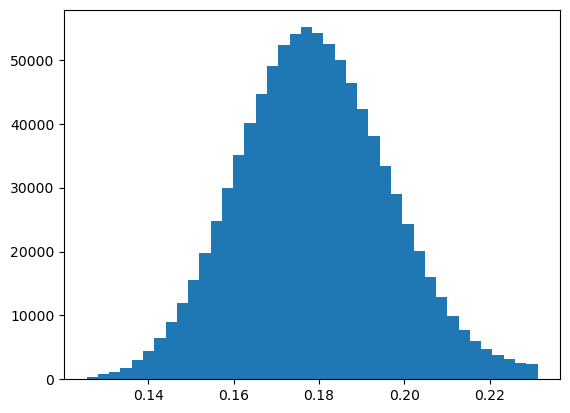

In [23]:
plt.hist(bkg_stats._get_values(bkg_stats.data_cutout),bins=40)

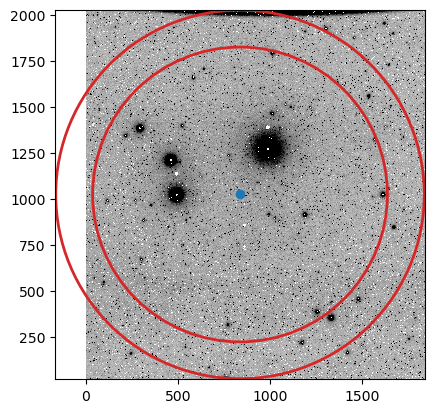

In [24]:
delta = r_out+3
vmin, vmax = get_min_max_plot(data_bkg_clean)
plt.imshow(data_bkg_clean, interpolation='nearest', vmin=vmin,vmax=vmax,cmap='Grays')
plt.plot(x_rel,y_rel,'o')
plt.xlim(x_rel-delta,x_rel+delta)
plt.ylim(y_rel-delta,y_rel+delta)
ann_patches = annulus_aperture.plot(color='tab:red', lw=2)

/var/folders/hw/9185wylx09g0rq_914h7mxlw0000gn/T/ipykernel_1994/1299670715.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs_test[0].legend(ncols=3)


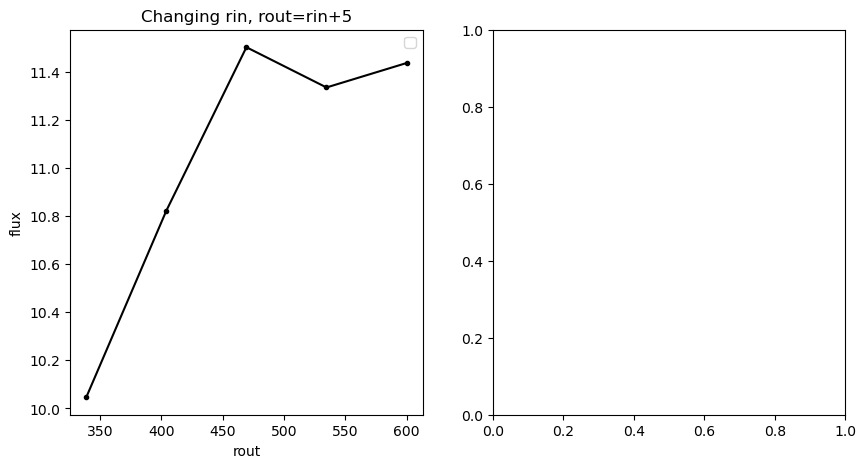

In [40]:
r_aperture, r_in, r_out = 5,8,10


f_test,axs_test = plt.subplots(1,2,figsize=(10,5))

r_in_test_all = np.linspace(12,600,10)
flux_array = []
for r_in_i in r_in_test_all:
    r_aperture_i = 10
    r_out_i = r_in_i + 5
    aper_flux,_,total_bkg,_ =  calculate_flux_and_bkg(x_rel, y_rel, image_data, image_data_err, 
                                                      flags_header, flags_data, r_aperture_i, r_in_i, r_out_i)
    apersum_bkgsub = aper_flux - total_bkg
    flux_array.append(apersum_bkgsub)

flux_array = np.array(flux_array).flatten()

axs_test[0].plot(r_in_test_all, flux_array, '.-', color='k')

axs_test[0].set_xlabel('rout')
axs_test[0].set_ylabel('flux')
axs_test[0].set_title('Changing rin, rout=rin+5')
axs_test[0].legend(ncols=3)


In [ ]:
i_known_data = 19
name = known_data['Name'][i_known_data]
ra_deg = known_data['ra'][i_known_data]
dec_deg = known_data['dec'][i_known_data]
pmra = known_data['pmra'][i_known_data]
pmdec = known_data['pmdec'][i_known_data]
epoch = known_data['epoch'][i_known_data]

coord = SkyCoord(ra_deg, dec_deg, unit='deg')
search_radius = 1 * u.arcsec
print(name)

# Following tutorial https://caltech-ipac.github.io/irsa-tutorials/spherex-intro/
Irsa.list_collections(filter='spherex')

results = Irsa.query_sia(pos=(coord, search_radius), collection='spherex_qr2')

if not os.path.exists(path_figures + name+'/'):
    os.makedirs(path_figures + name+'/')

results_spec = Table()

perc = 0.9 # Percentage of flux to choose r_aperture
test_external_ring = False

results_spec = extrac_spectrum(name,results,results_spec,ra_deg,dec_deg,pmra,pmdec,epoch,perc,test_external_ring,known_data,i_known_data,path_figures)

results_spec.write(path_data+'Spherex_spec_'+name+'.csv',format='csv',overwrite=True)